#  BRGS Brain Tumor MRI Classification
**Dataset:** Brain Tumor MRI (4 Classes)
**Task:** Multi-Class Classification
**Classes:** Glioma | Meningioma | No Tumor | Pituitary

##  Section 1: Install & Import Libraries

In [ ]:
# Install required libraries
!pip install -q tensorflow scikit-learn matplotlib seaborn opencv-python-headless grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 87.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATASET_PATH = '/content/drive/MyDrive/BRGS_brain-tumor-mri-dataset'

Mounted at /content/drive


In [ ]:
import os
print(os.listdir('/content/drive/MyDrive/'))

['Classroom', 'StudentInfo51-9.gsheet', 'Google AI Studio', 'Colab Notebooks', 'cvj.pdf', 'project_report', 'inbound597522523397282585.jpg', 'Video_folder_datasets', 'Lab Mid - 51(7) (2).gdoc', 'Lab Mid - 51(7) (1).gdoc', 'Lab Mid - 51(7).gdoc', 'cvj.gdoc', 'archive.zip', 'BRGS.zip', 'GraphBasics_Directed.gdoc', 'Class_1_2_Intro Cybersecurity and Digital Forensics (1).gdoc', 'Class_4_Cross Site Scripting (1).gdoc', 'Class_7_CORS_1.gdoc', 'Untitled document.gdoc', 'Class_1_2_Intro Cybersecurity and Digital Forensics.gdoc', 'Class_4_Cross Site Scripting.gdoc', 'SDP-400 group list.xlsx', 'BrainTumor_Checkpoints']


In [ ]:
import zipfile
print("Extracting...")
with zipfile.ZipFile('/content/drive/MyDrive/BRGS.zip', 'r') as z:
    z.extractall('/content/')
print("Done!")
print(os.listdir('/content/'))

Extracting...


In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score, precision_score, recall_score)
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB3, MobileNetV2
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import (EarlyStopping, ReduceLROnPlateau,
                                         ModelCheckpoint, CSVLogger)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

# Set seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print('✅ All libraries imported successfully!')
print(f'TensorFlow version: {tf.__version__}')
print(f'GPU Available: {len(tf.config.list_physical_devices("GPU")) > 0}')

## Section 2: Dataset Loading & Configuration

In [ ]:
# ============================================================
# CONFIGURATION — Change dataset path here if needed
# ============================================================
DATASET_PATH = '/content/BRGS_brain-tumor-mri-dataset'  # Update if needed
IMG_SIZE     = 224
BATCH_SIZE   = 32
EPOCHS_FAST  = 10    # Trial 1 & 2 quick check
EPOCHS_FULL  = 50    # Trial 3 full training
LR           = 1e-4

CLASS_NAMES  = ['glioma', 'meningioma', 'notumor', 'pituitary']
NUM_CLASSES  = len(CLASS_NAMES)

print(f' Dataset Path : {DATASET_PATH}')
print(f'  Image Size   : {IMG_SIZE}x{IMG_SIZE}')
print(f' Batch Size   : {BATCH_SIZE}')
print(f' Num Classes  : {NUM_CLASSES}')
print(f' Classes      : {CLASS_NAMES}')

##  Section 3: Data Visualization & EDA

In [ ]:
# Count images per class
class_counts = {}
all_paths    = []
all_labels   = []

for idx, cls in enumerate(CLASS_NAMES):
    folder = os.path.join(DATASET_PATH, cls)
    files  = [f for f in os.listdir(folder) if f.lower().endswith(('.jpg','.jpeg','.png'))]
    class_counts[cls] = len(files)
    for f in files:
        all_paths.append(os.path.join(folder, f))
        all_labels.append(idx)

total = sum(class_counts.values())
print('📊 Class Distribution:')
print('-' * 35)
for cls, cnt in class_counts.items():
    print(f'  {cls:15s}: {cnt:5d} images  ({cnt/total*100:.1f}%)')
print(f'  {"TOTAL":15s}: {total:5d} images')

# Check balance
max_c, min_c = max(class_counts.values()), min(class_counts.values())
imbalance_ratio = max_c / min_c
print(f'\n⚖️  Imbalance Ratio: {imbalance_ratio:.2f}x')
if imbalance_ratio > 1.5:
    print('⚠️  Dataset is IMBALANCED — applying class weights!')
else:
    print('✅ Dataset is relatively BALANCED')

In [ ]:
# ── Visualization: Class Distribution ──────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Brain Tumor MRI — Class Distribution', fontsize=15, fontweight='bold')

colors = ['#E74C3C', '#3498DB', '#2ECC71', '#9B59B6']

# Bar chart
axes[0].bar(CLASS_NAMES, class_counts.values(), color=colors, edgecolor='black', linewidth=0.8)
axes[0].set_title('Image Count per Class')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Count')
for i, (cls, cnt) in enumerate(class_counts.items()):
    axes[0].text(i, cnt + 20, str(cnt), ha='center', fontweight='bold')
axes[0].set_ylim(0, max(class_counts.values()) * 1.15)

# Pie chart
axes[1].pie(class_counts.values(), labels=CLASS_NAMES, colors=colors,
            autopct='%1.1f%%', startangle=90, pctdistance=0.85)
axes[1].set_title('Class Proportion')

plt.tight_layout()
plt.savefig('01_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Saved: 01_class_distribution.png')

In [ ]:
# ── Visualization: Sample Images ────────────────────────────
fig, axes = plt.subplots(4, 5, figsize=(16, 13))
fig.suptitle('Sample MRI Images — All Classes', fontsize=15, fontweight='bold')

for row, cls in enumerate(CLASS_NAMES):
    folder = os.path.join(DATASET_PATH, cls)
    files  = sorted(os.listdir(folder))[:5]
    for col, f in enumerate(files):
        img = cv2.imread(os.path.join(folder, f))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        axes[row, col].imshow(img)
        axes[row, col].axis('off')
        if col == 0:
            axes[row, col].set_title(cls.upper(), fontsize=11, fontweight='bold',
                                      color=colors[row], loc='left')

plt.tight_layout()
plt.savefig('02_sample_images.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Saved: 02_sample_images.png')

##  Section 4: Preprocessing

In [ ]:
def remove_gaussian_noise(img):
    """Remove Gaussian noise using Gaussian blur + bilateral filter."""
    denoised = cv2.GaussianBlur(img, (3, 3), 0)
    denoised = cv2.bilateralFilter(denoised, 9, 75, 75)
    return denoised

def apply_clahe(img):
    """Enhance contrast using CLAHE."""
    lab   = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    lab[:, :, 0] = clahe.apply(lab[:, :, 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def preprocess_image(path, size=IMG_SIZE):
    """Full preprocessing pipeline."""
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = remove_gaussian_noise(img)
    img = apply_clahe(img)
    img = cv2.resize(img, (size, size))
    img = img.astype(np.float32) / 255.0
    return img

print('🔧 Preprocessing functions defined!')
print('  ✅ Gaussian Noise Removal (Bilateral Filter)')
print('  ✅ CLAHE Contrast Enhancement')
print('  ✅ Resize to 224x224')
print('  ✅ Normalize [0, 1]')

In [ ]:
# ── Visualize Before vs After Preprocessing ─────────────────
sample_path = os.path.join(DATASET_PATH, 'glioma',
                           os.listdir(os.path.join(DATASET_PATH, 'glioma'))[0])

raw  = cv2.cvtColor(cv2.imread(sample_path), cv2.COLOR_BGR2RGB)
proc = (preprocess_image(sample_path) * 255).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle('Preprocessing Pipeline Visualization', fontsize=13, fontweight='bold')

axes[0].imshow(raw)
axes[0].set_title('Original Image')
axes[0].axis('off')

noisy = (np.clip(raw/255.0 + np.random.normal(0, 0.05, raw.shape), 0, 1)*255).astype(np.uint8)
axes[1].imshow(noisy)
axes[1].set_title('With Gaussian Noise')
axes[1].axis('off')

axes[2].imshow(proc)
axes[2].set_title('After Preprocessing\n(Denoised + CLAHE)')
axes[2].axis('off')

plt.tight_layout()
plt.savefig('03_preprocessing_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Saved: 03_preprocessing_comparison.png')

In [ ]:

import shutil, random

SPLIT_PATH = '/content/split_data'
for split in ['train', 'val', 'test']:
    for cls in CLASS_NAMES:
        os.makedirs(os.path.join(SPLIT_PATH, split, cls), exist_ok=True)

random.seed(42)
for cls in CLASS_NAMES:
    folder = os.path.join(DATASET_PATH, cls)
    files  = [f for f in os.listdir(folder) if f.lower().endswith(('.jpg','.jpeg','.png'))]
    random.shuffle(files)
    n = len(files)
    for f in files[:int(n*0.70)]:
        shutil.copy(os.path.join(folder,f), os.path.join(SPLIT_PATH,'train',cls,f))
    for f in files[int(n*0.70):int(n*0.85)]:
        shutil.copy(os.path.join(folder,f), os.path.join(SPLIT_PATH,'val',cls,f))
    for f in files[int(n*0.85):]:
        shutil.copy(os.path.join(folder,f), os.path.join(SPLIT_PATH,'test',cls,f))
    print(f'  {cls}: done')

train_datagen = ImageDataGenerator(rescale=1./255, rotation_range=15,
    width_shift_range=0.1, height_shift_range=0.1,
    horizontal_flip=True, zoom_range=0.1)
val_test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    os.path.join(SPLIT_PATH,'train'), target_size=(IMG_SIZE,IMG_SIZE),
    batch_size=BATCH_SIZE, class_mode='categorical', classes=CLASS_NAMES, seed=42)
val_gen = val_test_datagen.flow_from_directory(
    os.path.join(SPLIT_PATH,'val'), target_size=(IMG_SIZE,IMG_SIZE),
    batch_size=BATCH_SIZE, class_mode='categorical', classes=CLASS_NAMES)
test_gen = val_test_datagen.flow_from_directory(
    os.path.join(SPLIT_PATH,'test'), target_size=(IMG_SIZE,IMG_SIZE),
    batch_size=BATCH_SIZE, class_mode='categorical', classes=CLASS_NAMES, shuffle=False)

train_labels = train_gen.classes
cw = compute_class_weight('balanced', classes=np.unique(train_labels), y=train_labels)
class_weight_dict = dict(enumerate(cw))

print(f'\n✅ Train : {train_gen.samples}')
print(f'✅ Val   : {val_gen.samples}')
print(f'✅ Test  : {test_gen.samples}')
print(f'⚖️  Class Weights: {class_weight_dict}')

  glioma: done
  meningioma: done
  notumor: done
  pituitary: done
Found 5005 images belonging to 4 classes.
Found 1073 images belonging to 4 classes.
Found 1075 images belonging to 4 classes.

✅ Train : 5005
✅ Val   : 1073
✅ Test  : 1075
⚖️  Class Weights: {0: np.float64(1.103395061728395), 1: np.float64(1.0074476650563606), 2: np.float64(0.89375), 3: np.float64(1.0181041497152157)}


##  Section 5: Train / Validation / Test Split

📊 Train / Val / Test Split:
Class              Train      Val     Test    Total
---------------------------------------------
glioma              1134      243      244     1621
meningioma          1242      266      267     1775
notumor             1400      300      300     2000
pituitary           1229      264      264     1757
---------------------------------------------
TOTAL               5005     1073     1075     7153

  Train : 70%
  Val   : 15%
  Test  : 15%


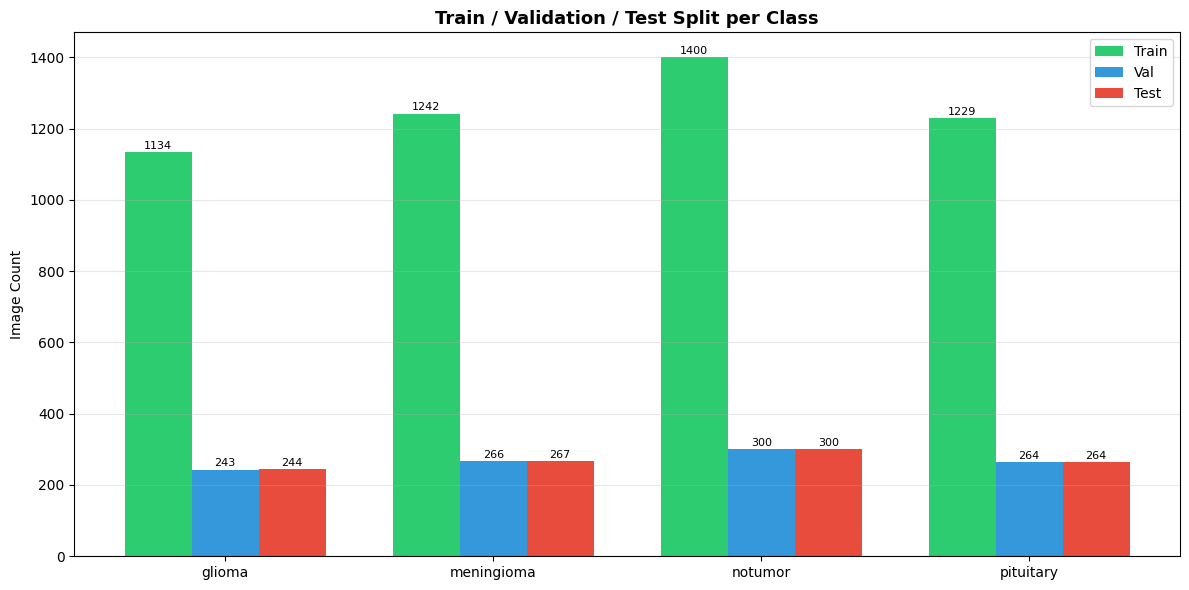

✅ Saved: 04_train_val_test_split.png


In [ ]:
# ── Train / Val / Test Split Visualization ───────────────────
train_counts = {cls: len(os.listdir(os.path.join(SPLIT_PATH,'train',cls))) for cls in CLASS_NAMES}
val_counts   = {cls: len(os.listdir(os.path.join(SPLIT_PATH,'val',  cls))) for cls in CLASS_NAMES}
test_counts  = {cls: len(os.listdir(os.path.join(SPLIT_PATH,'test', cls))) for cls in CLASS_NAMES}

print('📊 Train / Val / Test Split:')
print(f'{"Class":<15} {"Train":>8} {"Val":>8} {"Test":>8} {"Total":>8}')
print('-' * 45)
for cls in CLASS_NAMES:
    t = train_counts[cls]
    v = val_counts[cls]
    te = test_counts[cls]
    print(f'{cls:<15} {t:>8} {v:>8} {te:>8} {t+v+te:>8}')
print('-' * 45)
tt = sum(train_counts.values())
tv = sum(val_counts.values())
tte = sum(test_counts.values())
print(f'{"TOTAL":<15} {tt:>8} {tv:>8} {tte:>8} {tt+tv+tte:>8}')
print(f'\n  Train : {tt/(tt+tv+tte)*100:.0f}%')
print(f'  Val   : {tv/(tt+tv+tte)*100:.0f}%')
print(f'  Test  : {tte/(tt+tv+tte)*100:.0f}%')

# Bar chart
x   = np.arange(NUM_CLASSES)
w   = 0.25
fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(x-w, train_counts.values(), w, label='Train', color='#2ECC71')
ax.bar(x,   val_counts.values(),   w, label='Val',   color='#3498DB')
ax.bar(x+w, test_counts.values(),  w, label='Test',  color='#E74C3C')
ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES)
ax.set_title('Train / Validation / Test Split per Class', fontsize=13, fontweight='bold')
ax.set_ylabel('Image Count')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
for i in range(NUM_CLASSES):
    ax.text(i-w, list(train_counts.values())[i]+10, str(list(train_counts.values())[i]), ha='center', fontsize=8)
    ax.text(i,   list(val_counts.values())[i]+10,   str(list(val_counts.values())[i]),   ha='center', fontsize=8)
    ax.text(i+w, list(test_counts.values())[i]+10,  str(list(test_counts.values())[i]),  ha='center', fontsize=8)
plt.tight_layout()
plt.savefig('04_train_val_test_split.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Saved: 04_train_val_test_split.png')

In [ ]:
print(f'⚖️  Class Weights: {class_weight_dict}')
print(f'\n✅ Train : {train_gen.samples}')
print(f'✅ Val   : {val_gen.samples}')
print(f'✅ Test  : {test_gen.samples}')

⚖️  Class Weights: {0: np.float64(1.103395061728395), 1: np.float64(1.0074476650563606), 2: np.float64(0.89375), 3: np.float64(1.0181041497152157)}

✅ Train : 5005
✅ Val   : 1073
✅ Test  : 1075


In [ ]:
# Extract numpy arrays from generators
print("Extracting validation data...")
X_val, y_val_cat = [], []
val_gen.reset()
for i in range(len(val_gen)):
    x_batch, y_batch = val_gen[i]
    X_val.append(x_batch)
    y_val_cat.append(y_batch)
X_val = np.concatenate(X_val, axis=0)
y_val_cat = np.concatenate(y_val_cat, axis=0)
y_val = np.argmax(y_val_cat, axis=1)

print("Extracting test data...")
X_test, y_test_cat = [], []
test_gen.reset()
for i in range(len(test_gen)):
    x_batch, y_batch = test_gen[i]
    X_test.append(x_batch)
    y_test_cat.append(y_batch)
X_test = np.concatenate(X_test, axis=0)
y_test_cat = np.concatenate(y_test_cat, axis=0)
y_test = np.argmax(y_test_cat, axis=1)

print(f"✅ X_val shape : {X_val.shape}")
print(f"✅ X_test shape: {X_test.shape}")

Extracting validation data...
Extracting test data...
✅ X_val shape : (1073, 224, 224, 3)
✅ X_test shape: (1075, 224, 224, 3)


##  Section 6: Hybrid Model Architecture

In [ ]:
def build_hybrid_model(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES):
    """
    Hybrid Model: EfficientNetB3 + MobileNetV2 + Attention
    Both backbones extract features → Concatenate → Attention → Classify
    """
    inputs = keras.Input(shape=input_shape)

    # ── Branch 1: EfficientNetB3 ────────────────────────────
    effnet = EfficientNetB3(include_top=False, weights='imagenet',
                            input_tensor=inputs)
    effnet.trainable = False   # Freeze initially
    branch1 = effnet.output
    branch1 = layers.GlobalAveragePooling2D(name='gap_effnet')(branch1)
    branch1 = layers.Dense(256, activation='relu', name='dense_effnet')(branch1)
    branch1 = layers.BatchNormalization()(branch1)
    branch1 = layers.Dropout(0.3)(branch1)

    # ── Branch 2: MobileNetV2 ───────────────────────────────
    mobilenet = MobileNetV2(include_top=False, weights='imagenet',
                            input_tensor=inputs)
    mobilenet.trainable = False
    branch2 = mobilenet.output
    branch2 = layers.GlobalAveragePooling2D(name='gap_mobilenet')(branch2)
    branch2 = layers.Dense(256, activation='relu', name='dense_mobilenet')(branch2)
    branch2 = layers.BatchNormalization()(branch2)
    branch2 = layers.Dropout(0.3)(branch2)

    # ── Merge & Attention ───────────────────────────────────
    merged = layers.Concatenate(name='merge')([branch1, branch2])

    # Channel Attention (Squeeze-and-Excitation)
    attn = layers.Dense(512 // 8, activation='relu', name='attn_squeeze')(merged)
    attn = layers.Dense(512, activation='sigmoid', name='attn_excite')(attn)
    attended = layers.Multiply(name='attended')([merged, attn])

    # ── Classifier Head ─────────────────────────────────────
    x = layers.Dense(256, activation='relu')(attended)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax', name='output')(x)

    model = Model(inputs=inputs, outputs=outputs, name='HybridBrainTumorModel')
    return model

model = build_hybrid_model()
model.summary()
print('\n✅ Hybrid Model (EfficientNetB3 + MobileNetV2 + Attention) built!')

43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "HybridBrainTumorModel"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │      1,080 │ stem_conv_pad[0]… │
│                     │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        160 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        360 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        160 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 40)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 40)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 10)  │        410 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 40)  │        440 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 40)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        960 │ block1a_se_excit

 Total params: 13,996,851 (53.39 MB)

 Trainable params: 953,796 (3.64 MB)

 Non-trainable params: 13,043,055 (49.76 MB)


✅ Hybrid Model (EfficientNetB3 + MobileNetV2 + Attention) built!


##  Section 7: Training — Trial 1 (10 Epochs, Quick Check)

🚀 Trial 1: Training with frozen backbones (10 epochs)...
Epoch 1/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 709ms/step - accuracy: 0.3925 - loss: 1.7299
Epoch 1: val_accuracy improved from None to 0.73253, saving model to /content/drive/MyDrive/BrainTumor_Checkpoints/best_trial1.keras

Epoch 1: finished saving model to /content/drive/MyDrive/BrainTumor_Checkpoints/best_trial1.keras
157/157 ━━━━━━━━━━━━━━━━━━━━ 229s 1s/step - accuracy: 0.5031 - loss: 1.3574 - val_accuracy: 0.7325 - val_loss: 0.8554 - learning_rate: 1.0000e-04
Epoch 2/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 428ms/step - accuracy: 0.6777 - loss: 0.8501
Epoch 2: val_accuracy improved from 0.73253 to 0.77819, saving model to /content/drive/MyDrive/BrainTumor_Checkpoints/best_trial1.keras

Epoch 2: finished saving model to /content/drive/MyDrive/BrainTumor_Checkpoints/best_trial1.keras
157/157 ━━━━━━━━━━━━━━━━━━━━ 75s 473ms/step - accuracy: 0.7139 - loss: 0.7692 - val_accuracy: 0.7782 - val_loss: 0.5627 - learning_rate: 1.0000e-04
Epoch 

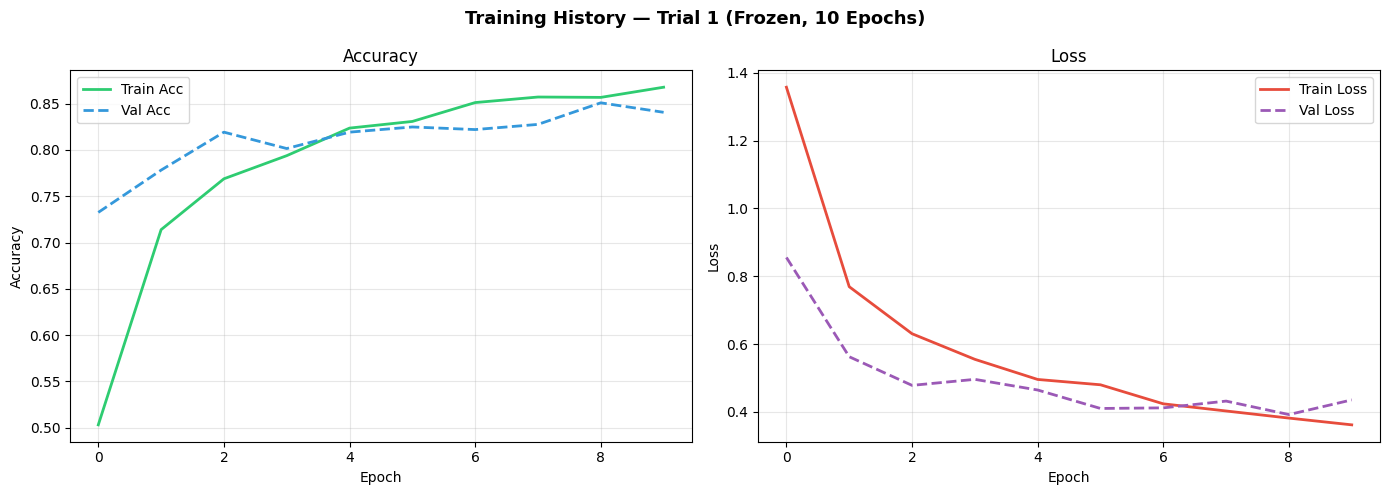

In [ ]:
def get_callbacks(trial_name):
    return [
        EarlyStopping(monitor='val_accuracy', patience=5,
                      restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                          patience=3, min_lr=1e-7, verbose=1),
 ModelCheckpoint(f'/content/drive/MyDrive/BrainTumor_Checkpoints/best_{trial_name}.keras',
                        monitor='val_accuracy', save_best_only=True, verbose=1),
        CSVLogger(f'log_{trial_name}.csv')
    ]

def plot_history(history, trial_name):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f'Training History — {trial_name}', fontsize=13, fontweight='bold')

    # Accuracy
    axes[0].plot(history.history['accuracy'],     label='Train Acc',  color='#2ECC71', lw=2)
    axes[0].plot(history.history['val_accuracy'], label='Val Acc',    color='#3498DB', lw=2, linestyle='--')
    axes[0].set_title('Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Loss
    axes[1].plot(history.history['loss'],     label='Train Loss', color='#E74C3C', lw=2)
    axes[1].plot(history.history['val_loss'], label='Val Loss',   color='#9B59B6', lw=2, linestyle='--')
    axes[1].set_title('Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(f'history_{trial_name}.png', dpi=150, bbox_inches='tight')
    plt.show()

# ── TRIAL 1: Frozen backbone, 10 epochs ──────────────────────
model.compile(
    optimizer=Adam(LR),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print('🚀 Trial 1: Training with frozen backbones (10 epochs)...')
history_t1 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_FAST,
    class_weight=class_weight_dict,
    callbacks=get_callbacks('trial1'),
    verbose=1
)

plot_history(history_t1, 'Trial 1 (Frozen, 10 Epochs)')

##  Section 8: Training — Trial 2 (Fine-tuning Last Layers)

🚀 Trial 2: Fine-tuning (unfreezing top layers, 10 epochs)...
Epoch 1/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 591ms/step - accuracy: 0.8730 - loss: 0.3565
Epoch 1: val_accuracy improved from None to 0.84436, saving model to /content/drive/MyDrive/BrainTumor_Checkpoints/best_trial2.keras

Epoch 1: finished saving model to /content/drive/MyDrive/BrainTumor_Checkpoints/best_trial2.keras
157/157 ━━━━━━━━━━━━━━━━━━━━ 178s 812ms/step - accuracy: 0.8711 - loss: 0.3579 - val_accuracy: 0.8444 - val_loss: 0.4152 - learning_rate: 1.0000e-05
Epoch 2/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 455ms/step - accuracy: 0.8727 - loss: 0.3463
Epoch 2: val_accuracy did not improve from 0.84436
157/157 ━━━━━━━━━━━━━━━━━━━━ 76s 480ms/step - accuracy: 0.8671 - loss: 0.3688 - val_accuracy: 0.8397 - val_loss: 0.4308 - learning_rate: 1.0000e-05
Epoch 3/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 436ms/step - accuracy: 0.8762 - loss: 0.3457
Epoch 3: val_accuracy did not improve from 0.84436
157/157 ━━━━━━━━━━━━━━━━━━━━ 72s 461ms/step 

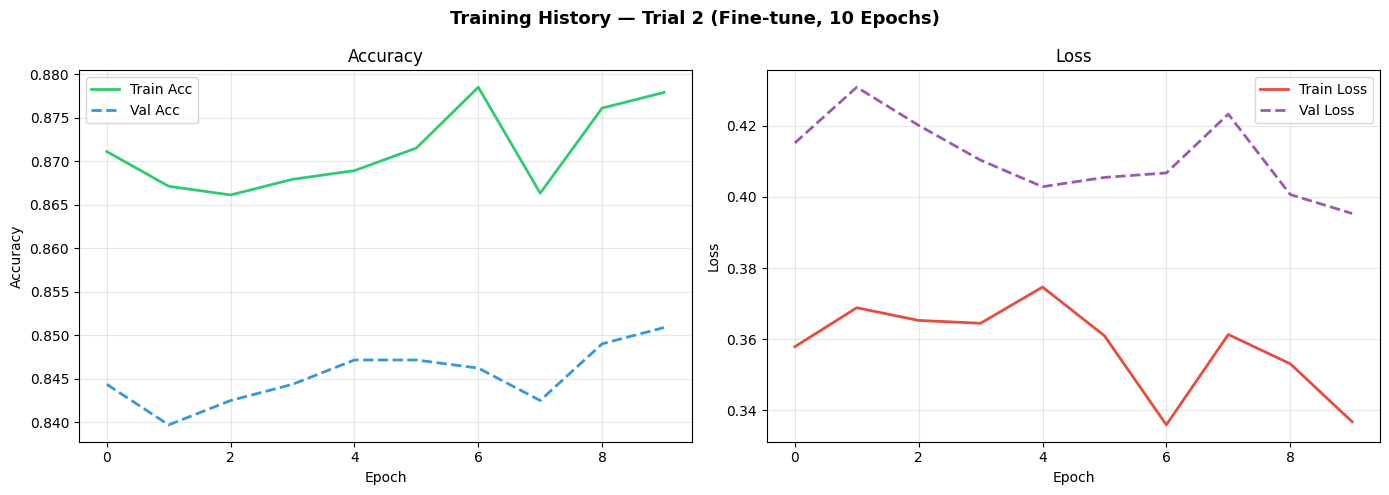

In [ ]:
# ── TRIAL 2: Unfreeze top layers, fine-tune ──────────────────
# Unfreeze last 30 layers of each backbone
for layer in model.layers:
    if hasattr(layer, 'layers'):   # It's a sub-model
        for sub in layer.layers[-30:]:
            sub.trainable = True

model.compile(
    optimizer=Adam(LR / 10),   # Lower LR for fine-tuning
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print('🚀 Trial 2: Fine-tuning (unfreezing top layers, 10 epochs)...')
history_t2 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS_FAST,
    class_weight=class_weight_dict,
    callbacks=get_callbacks('trial2'),
    verbose=1
)

plot_history(history_t2, 'Trial 2 (Fine-tune, 10 Epochs)')

##  Section 9: Training — Trial 3 (Full Training, 30 Epochs)

🚀 Trial 3: Full training (30 epochs)...
Epoch 1/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5077 - loss: 1.3143
Epoch 1: val_accuracy improved from None to 0.58341, saving model to /content/drive/MyDrive/BrainTumor_Checkpoints/best_trial3.keras

Epoch 1: finished saving model to /content/drive/MyDrive/BrainTumor_Checkpoints/best_trial3.keras
157/157 ━━━━━━━━━━━━━━━━━━━━ 515s 2s/step - accuracy: 0.6631 - loss: 0.8822 - val_accuracy: 0.5834 - val_loss: 1.0825 - learning_rate: 1.0000e-04
Epoch 2/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 580ms/step - accuracy: 0.8472 - loss: 0.4084
Epoch 2: val_accuracy did not improve from 0.58341
157/157 ━━━━━━━━━━━━━━━━━━━━ 95s 602ms/step - accuracy: 0.8773 - loss: 0.3450 - val_accuracy: 0.5126 - val_loss: 1.5009 - learning_rate: 2.0000e-04
Epoch 3/30
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 556ms/step - accuracy: 0.9247 - loss: 0.2187
Epoch 3: val_accuracy did not improve from 0.58341
157/157 ━━━━━━━━━━━━━━━━━━━━ 91s 578ms/step - accuracy: 0.9273 - loss: 

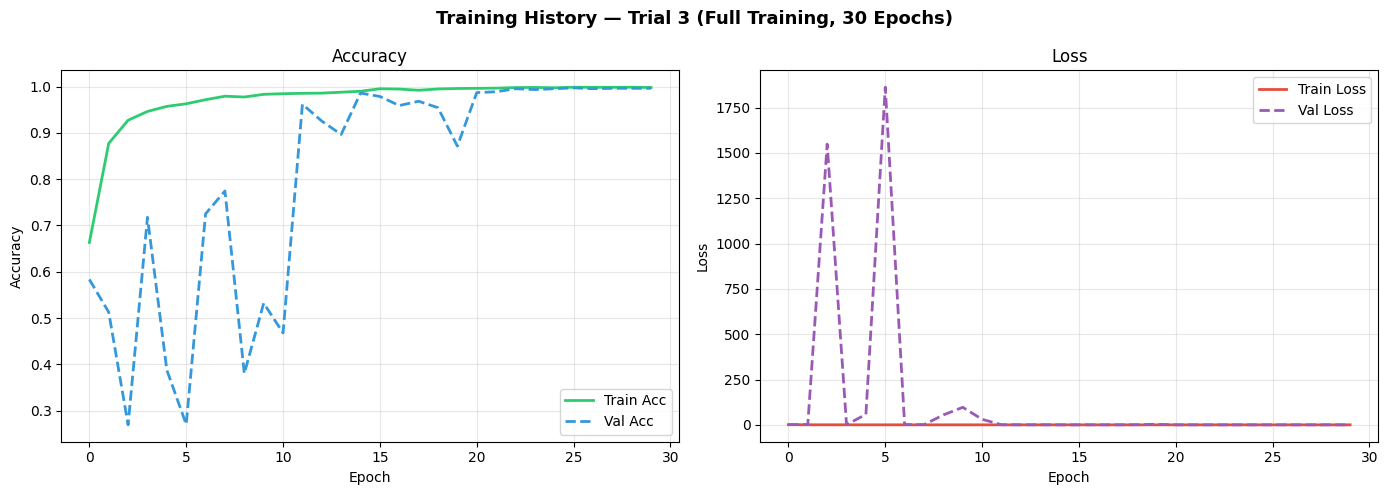

In [ ]:
def plot_history(history, trial_name):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f'Training History — {trial_name}', fontsize=13, fontweight='bold')

    axes[0].plot(history.history['accuracy'],     label='Train Acc',  color='#2ECC71', lw=2)
    axes[0].plot(history.history['val_accuracy'], label='Val Acc',    color='#3498DB', lw=2, linestyle='--')
    axes[0].set_title('Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(history.history['loss'],     label='Train Loss', color='#E74C3C', lw=2)
    axes[1].plot(history.history['val_loss'], label='Val Loss',   color='#9B59B6', lw=2, linestyle='--')
    axes[1].set_title('Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(f'history_{trial_name}.png', dpi=150, bbox_inches='tight')
    plt.show()

model3 = build_hybrid_model()
for layer in model3.layers:
    layer.trainable = True

LR_T3 = 3e-4

def cosine_lr_schedule(epoch, lr):
    if epoch < 3:
        return float(LR_T3 * (epoch + 1) / 3)
    progress = (epoch - 3) / (30 - 3)
    return float(LR_T3 * 0.5 * (1 + np.cos(np.pi * progress)))

optimizer = Adam(LR_T3, clipnorm=1.0)

model3.compile(
    optimizer=optimizer,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

callbacks3 = [
    EarlyStopping(monitor='val_accuracy', patience=30,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=3, min_lr=1e-8, verbose=1),
    ModelCheckpoint('/content/drive/MyDrive/BrainTumor_Checkpoints/best_trial3.keras',
                    monitor='val_accuracy', save_best_only=True, verbose=1),
    CSVLogger('log_trial3.csv'),
    keras.callbacks.LearningRateScheduler(cosine_lr_schedule, verbose=0)
]

print('🚀 Trial 3: Full training (30 epochs)...')
h3 = model3.fit(
    train_gen,
    validation_data=val_gen,
    epochs=30,
    class_weight=class_weight_dict,
    callbacks=callbacks3,
    verbose=1
)

plot_history(h3, 'Trial 3 (Full Training, 30 Epochs)')

##  Section 10: Select Best Model & Evaluate

In [ ]:
CKPT_DIR = '/content/drive/MyDrive/BrainTumor_Checkpoints'

results = {}

for trial in ['trial1', 'trial2', 'trial3']:
    path = f'{CKPT_DIR}/best_{trial}.keras'
    if os.path.exists(path):
        m = keras.models.load_model(path)
        test_gen.reset()
        loss, acc = m.evaluate(test_gen, verbose=0)
        results[trial] = {'model': m, 'val_acc': acc, 'val_loss': loss}
        print(f'  {trial}: Val Acc = {acc:.4f} | Val Loss = {loss:.4f}')
    else:
        print(f'  ⚠️ {trial}: checkpoint not found at {path}')

if not results:
    raise RuntimeError("কোনো checkpoint পাওয়া যায়নি — path ঠিক আছে কিনা এবং Trial 1/2/3 আসলে সফলভাবে save হয়েছে কিনা Drive-এ গিয়ে check করুন।")

best_trial = max(results, key=lambda k: results[k]['val_acc'])
best_model = results[best_trial]['model']
print(f'\n🏆 Best Model: {best_trial}')

  trial1: Val Acc = 0.8670 | Val Loss = 0.3519
  trial2: Val Acc = 0.8679 | Val Loss = 0.3554
  trial3: Val Acc = 0.9916 | Val Loss = 0.0493

🏆 Best Model: trial3


##  Section 11: Results — Metrics (Accuracy, Loss, Precision, Recall, F1 Macro)

In [ ]:


# ── Predictions ─────────────────────────────────────────────
test_gen.reset()
y_pred_prob = best_model.predict(test_gen, verbose=1)
y_pred      = np.argmax(y_pred_prob, axis=1)
y_test      = test_gen.classes

# ── Metrics ─────────────────────────────────────────────────
test_gen.reset()
test_loss, test_acc = best_model.evaluate(test_gen, verbose=0)
val_gen.reset()
val_loss, val_acc   = best_model.evaluate(val_gen, verbose=0)

precision_macro = precision_score(y_test, y_pred, average='macro')
recall_macro    = recall_score(y_test,    y_pred, average='macro')
f1_macro        = f1_score(y_test,        y_pred, average='macro')

print('=' * 50)
print('       FINAL RESULTS — BEST MODEL')
print('=' * 50)
print(f'  Validation Accuracy : {val_acc:.4f}  ({val_acc*100:.2f}%)')
print(f'  Validation Loss     : {val_loss:.4f}')
print(f'  Test Accuracy       : {test_acc:.4f}  ({test_acc*100:.2f}%)')
print(f'  Test Loss           : {test_loss:.4f}')
print('-' * 50)
print(f'  Precision (Macro)   : {precision_macro:.4f}')
print(f'  Recall    (Macro)   : {recall_macro:.4f}')
print(f'  F1 Score  (Macro)   : {f1_macro:.4f}')
print('=' * 50)
print('\n📋 Classification Report:')
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES))

34/34 ━━━━━━━━━━━━━━━━━━━━ 34s 562ms/step
       FINAL RESULTS — BEST MODEL
  Validation Accuracy : 0.9972  (99.72%)
  Validation Loss     : 0.0139
  Test Accuracy       : 0.9916  (99.16%)
  Test Loss           : 0.0493
--------------------------------------------------
  Precision (Macro)   : 0.9914
  Recall    (Macro)   : 0.9917
  F1 Score  (Macro)   : 0.9915

📋 Classification Report:
              precision    recall  f1-score   support

      glioma       0.99      1.00      0.99       244
  meningioma       0.99      0.99      0.99       267
     notumor       1.00      0.99      1.00       300
   pituitary       0.98      0.99      0.99       264

    accuracy                           0.99      1075
   macro avg       0.99      0.99      0.99      1075
weighted avg       0.99      0.99      0.99      1075



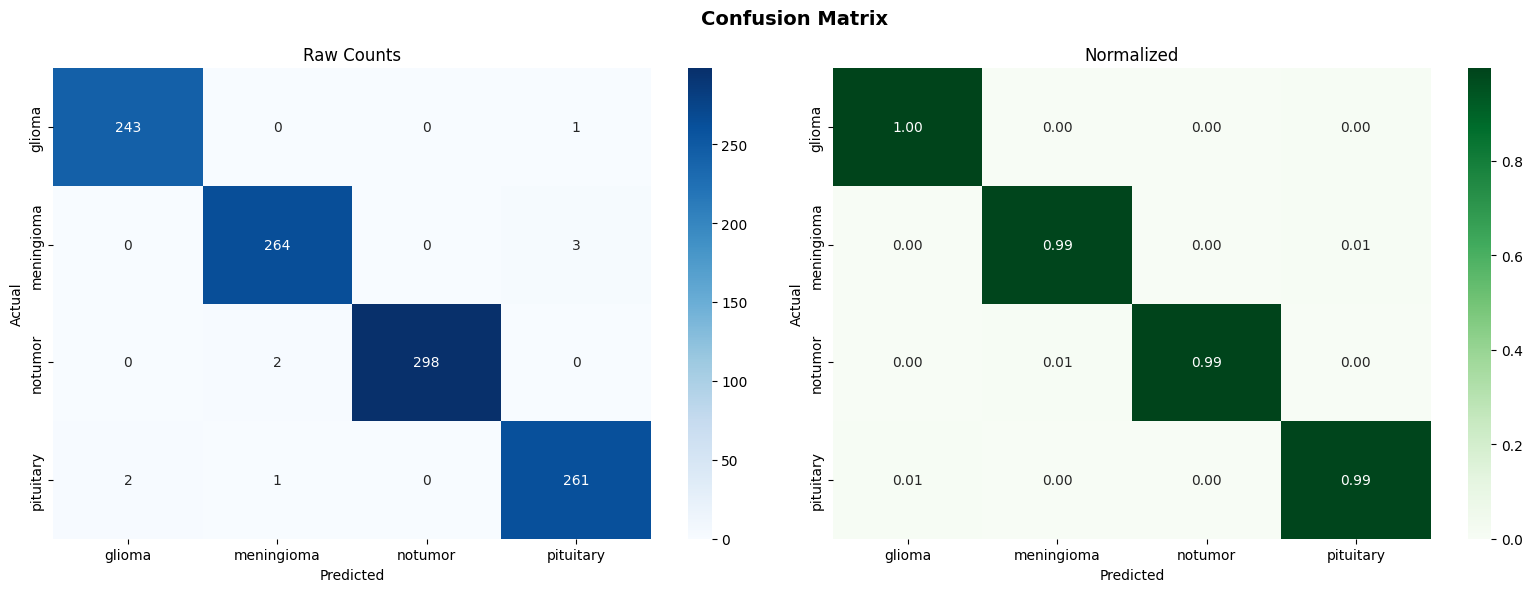

✅ Saved: 05_confusion_matrix.png


In [ ]:
# ── Confusion Matrix ─────────────────────────────────────────
cm = confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Confusion Matrix', fontsize=14, fontweight='bold')

# Raw counts
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title('Raw Counts')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Normalized
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1])
axes[1].set_title('Normalized')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.savefig('05_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Saved: 05_confusion_matrix.png')

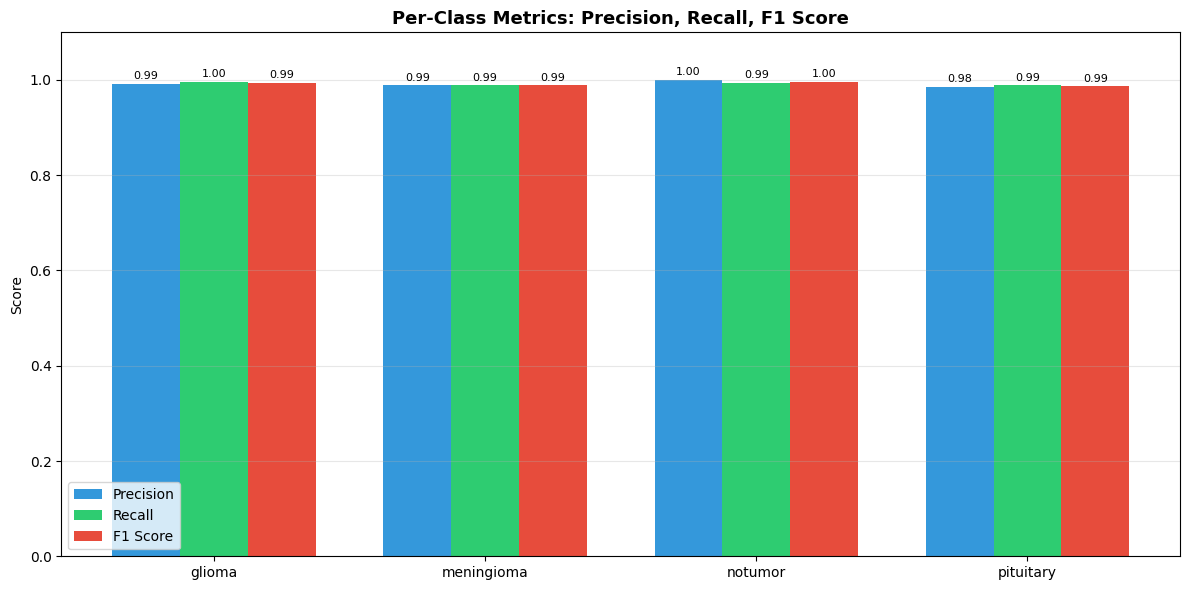

✅ Saved: 06_per_class_metrics.png


In [ ]:
# ── Per-Class Metrics Bar Chart ──────────────────────────────
from sklearn.metrics import precision_recall_fscore_support
prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred)

x = np.arange(NUM_CLASSES)
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(x - width, prec, width, label='Precision', color='#3498DB')
ax.bar(x,         rec,  width, label='Recall',    color='#2ECC71')
ax.bar(x + width, f1,   width, label='F1 Score',  color='#E74C3C')

ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Score')
ax.set_title('Per-Class Metrics: Precision, Recall, F1 Score', fontsize=13, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

for i in range(NUM_CLASSES):
    ax.text(i - width, prec[i] + 0.01, f'{prec[i]:.2f}', ha='center', fontsize=8)
    ax.text(i,         rec[i]  + 0.01, f'{rec[i]:.2f}',  ha='center', fontsize=8)
    ax.text(i + width, f1[i]   + 0.01, f'{f1[i]:.2f}',   ha='center', fontsize=8)

plt.tight_layout()
plt.savefig('06_per_class_metrics.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Saved: 06_per_class_metrics.png')

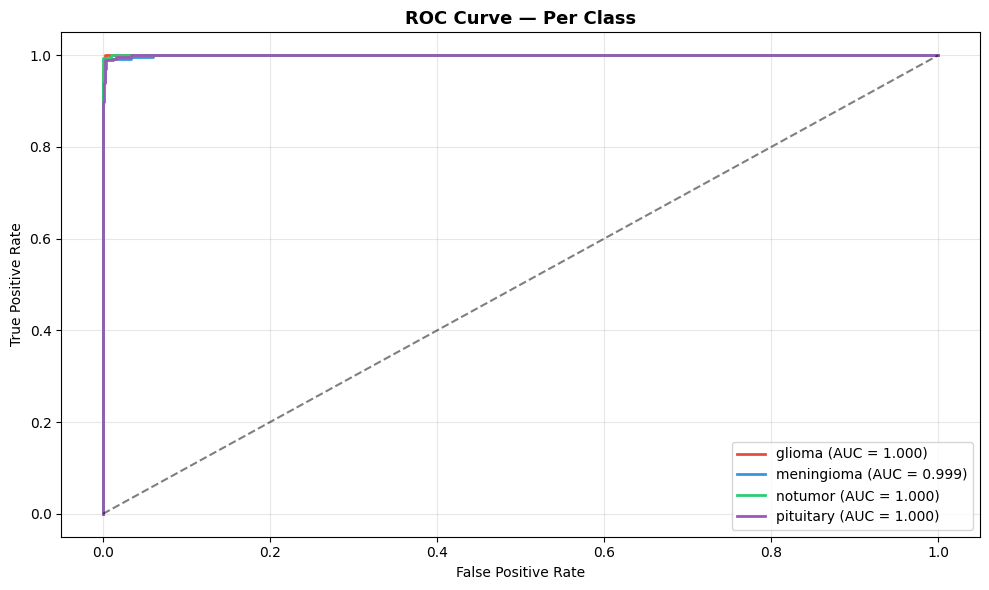

✅ Macro AUC Score: 0.9997


In [ ]:
# ── ROC Curve ────────────────────────────────────────────────
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

y_test_bin = label_binarize(y_test, classes=range(NUM_CLASSES))

fpr, tpr, roc_auc = {}, {}, {}
for i in range(NUM_CLASSES):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_pred_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(10, 6))
colors_roc = ['#E74C3C', '#3498DB', '#2ECC71', '#9B59B6']
for i, cls in enumerate(CLASS_NAMES):
    plt.plot(fpr[i], tpr[i], color=colors_roc[i],
             label=f'{cls} (AUC = {roc_auc[i]:.3f})', lw=2)
plt.plot([0,1],[0,1],'k--', alpha=0.5)
plt.title('ROC Curve — Per Class', fontsize=13, fontweight='bold')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('10_roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()

macro_auc = np.mean(list(roc_auc.values()))
print(f'✅ Macro AUC Score: {macro_auc:.4f}')

##  Section 12: XAI — Grad-CAM Visualization

🔍 Generating Grad-CAM visualizations...


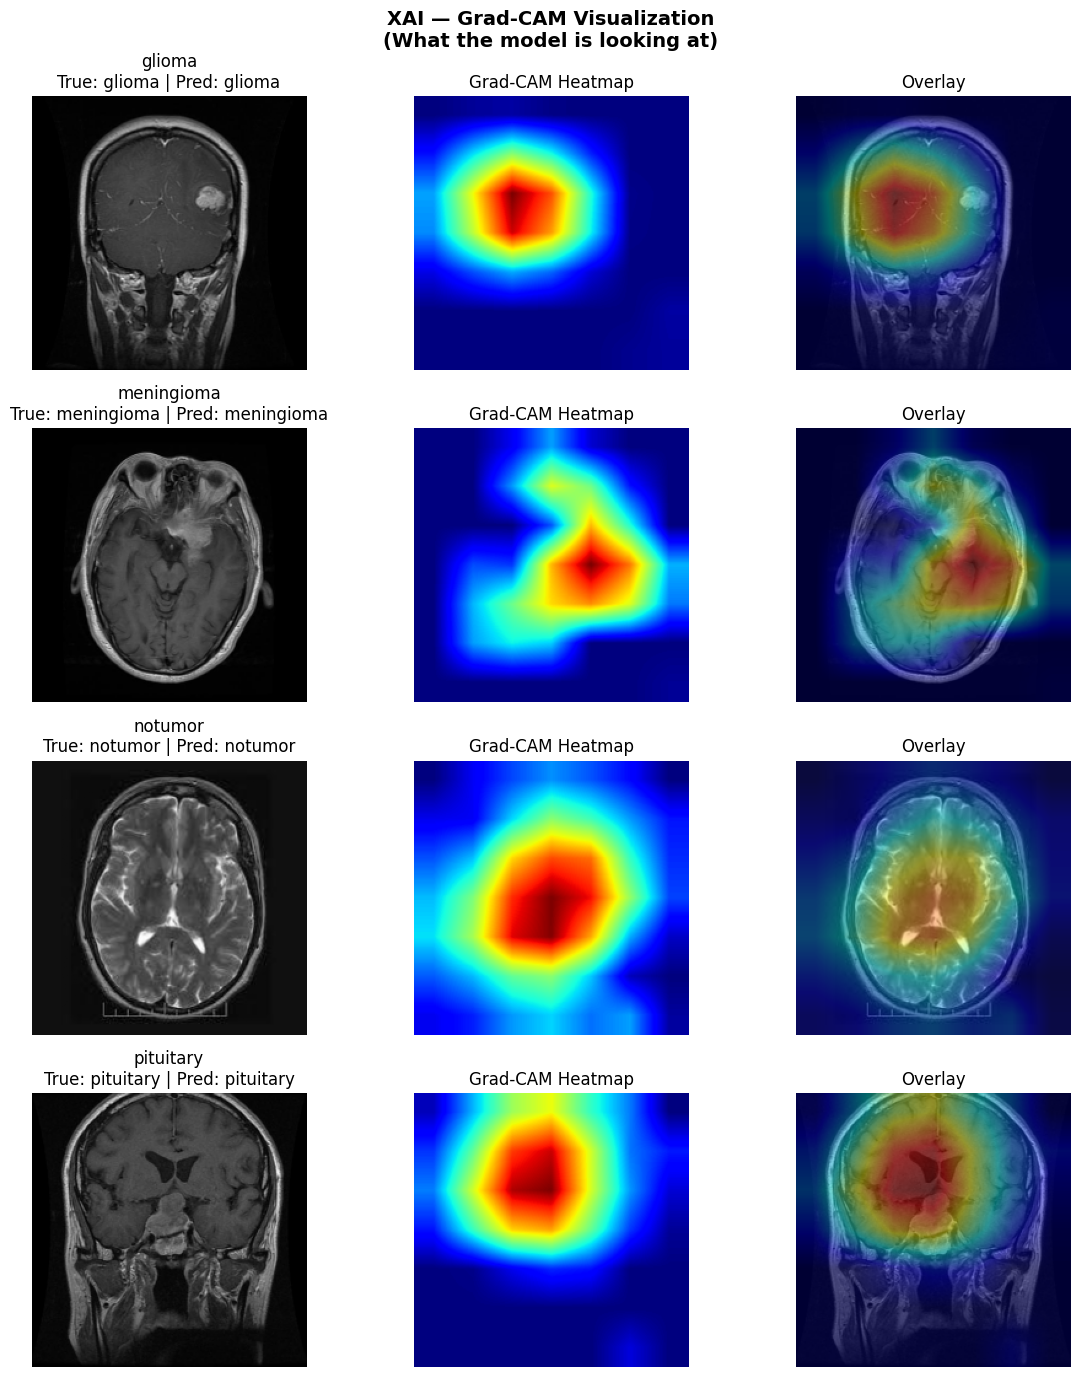

✅ Saved: 07_gradcam_xai.png


In [ ]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        inputs = tf.cast(img_array, tf.float32)
        conv_outputs, predictions = grad_model(inputs)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]
    grads    = tape.gradient(class_channel, conv_outputs)
    pooled   = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_out = conv_outputs[0]
    heatmap  = conv_out @ pooled[..., tf.newaxis]
    heatmap  = tf.squeeze(heatmap)
    heatmap  = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

def overlay_gradcam(img, heatmap, alpha=0.4):
    heatmap_resized = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
    img_uint8 = np.uint8(255 * img)
    overlay   = cv2.addWeighted(img_uint8, 1 - alpha, heatmap_colored, alpha, 0)
    return overlay

last_conv_layer = 'top_conv'
print('🔍 Generating Grad-CAM visualizations...')

# ✅ FIX: pull one real image per class directly from the full file list,
# instead of the first 160 sequential images (which were all glioma).
filepaths    = test_gen.filepaths      # full test set paths, in generator order
true_labels  = np.array(test_gen.classes)  # aligned true label per file

fig, axes = plt.subplots(NUM_CLASSES, 3, figsize=(12, 14))
fig.suptitle('XAI — Grad-CAM Visualization\n(What the model is looking at)',
             fontsize=14, fontweight='bold')

for cls_idx, cls_name in enumerate(CLASS_NAMES):
    cls_file_indices = np.where(true_labels == cls_idx)[0]
    if len(cls_file_indices) == 0:
        print(f'⚠️ No test images found for class {cls_name}')
        continue

    chosen = cls_file_indices[0]           # first file of this class
    raw = cv2.imread(filepaths[chosen])
    raw = cv2.cvtColor(raw, cv2.COLOR_BGR2RGB)
    raw = cv2.resize(raw, (IMG_SIZE, IMG_SIZE))
    img = raw.astype('float32') / 255.0
    img_array = np.expand_dims(img, axis=0)

    pred = int(np.argmax(best_model.predict(img_array, verbose=0), axis=1)[0])

    try:
        heatmap = make_gradcam_heatmap(img_array, best_model, last_conv_layer, pred)
        overlay = overlay_gradcam(img, heatmap)
        heatmap_vis = cv2.resize(heatmap, (IMG_SIZE, IMG_SIZE))
    except Exception as e:
        print(f'Grad-CAM failed for {cls_name}: {e}')
        heatmap_vis = np.zeros((IMG_SIZE, IMG_SIZE))
        overlay = (img * 255).astype(np.uint8)

    axes[cls_idx, 0].imshow(img)
    axes[cls_idx, 0].set_title(f'{cls_name}\nTrue: {cls_name} | Pred: {CLASS_NAMES[pred]}')
    axes[cls_idx, 0].axis('off')

    axes[cls_idx, 1].imshow(heatmap_vis, cmap='jet')
    axes[cls_idx, 1].set_title('Grad-CAM Heatmap')
    axes[cls_idx, 1].axis('off')

    axes[cls_idx, 2].imshow(overlay)
    axes[cls_idx, 2].set_title('Overlay')
    axes[cls_idx, 2].axis('off')

plt.tight_layout()
plt.savefig('07_gradcam_xai.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Saved: 07_gradcam_xai.png')

## Section 13: Model Response — Qualitative & Quantitative

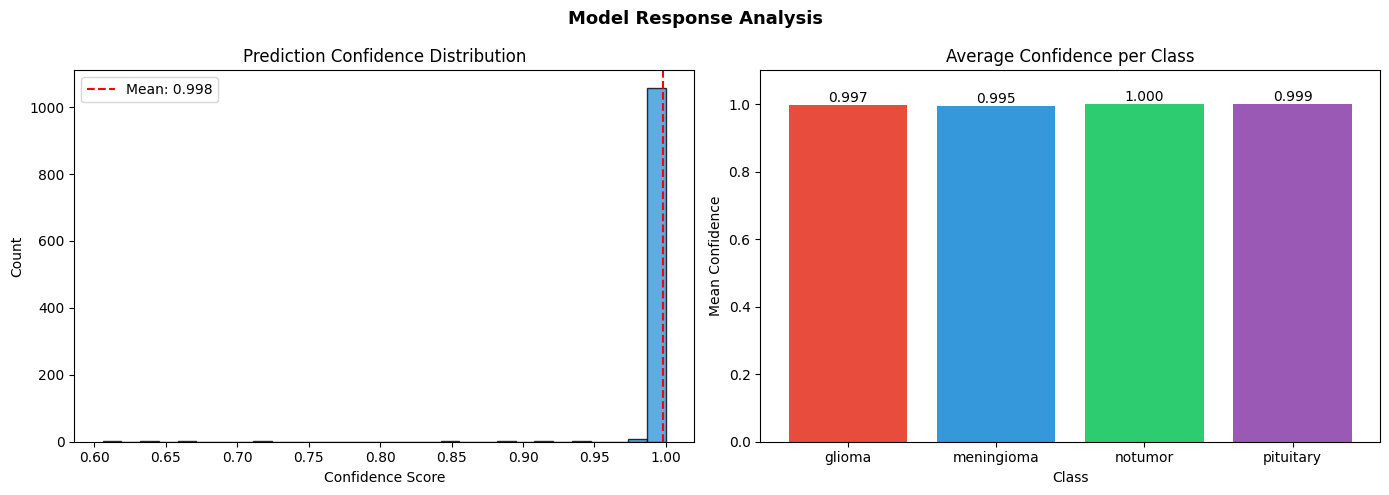

✅ Saved: 08_model_response.png


In [ ]:
# ── Prediction Confidence Distribution ──────────────────────
confidence = np.max(y_pred_prob, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Model Response Analysis', fontsize=13, fontweight='bold')

# Confidence histogram
axes[0].hist(confidence, bins=30, color='#3498DB', edgecolor='black', alpha=0.8)
axes[0].axvline(confidence.mean(), color='red', linestyle='--',
                label=f'Mean: {confidence.mean():.3f}')
axes[0].set_title('Prediction Confidence Distribution')
axes[0].set_xlabel('Confidence Score')
axes[0].set_ylabel('Count')
axes[0].legend()

# Per-class confidence
cls_conf = [confidence[y_test == i].mean() for i in range(NUM_CLASSES)]
axes[1].bar(CLASS_NAMES, cls_conf, color=colors)
axes[1].set_title('Average Confidence per Class')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Mean Confidence')
axes[1].set_ylim(0, 1.1)
for i, v in enumerate(cls_conf):
    axes[1].text(i, v + 0.01, f'{v:.3f}', ha='center', fontsize=10)

plt.tight_layout()
plt.savefig('08_model_response.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Saved: 08_model_response.png')

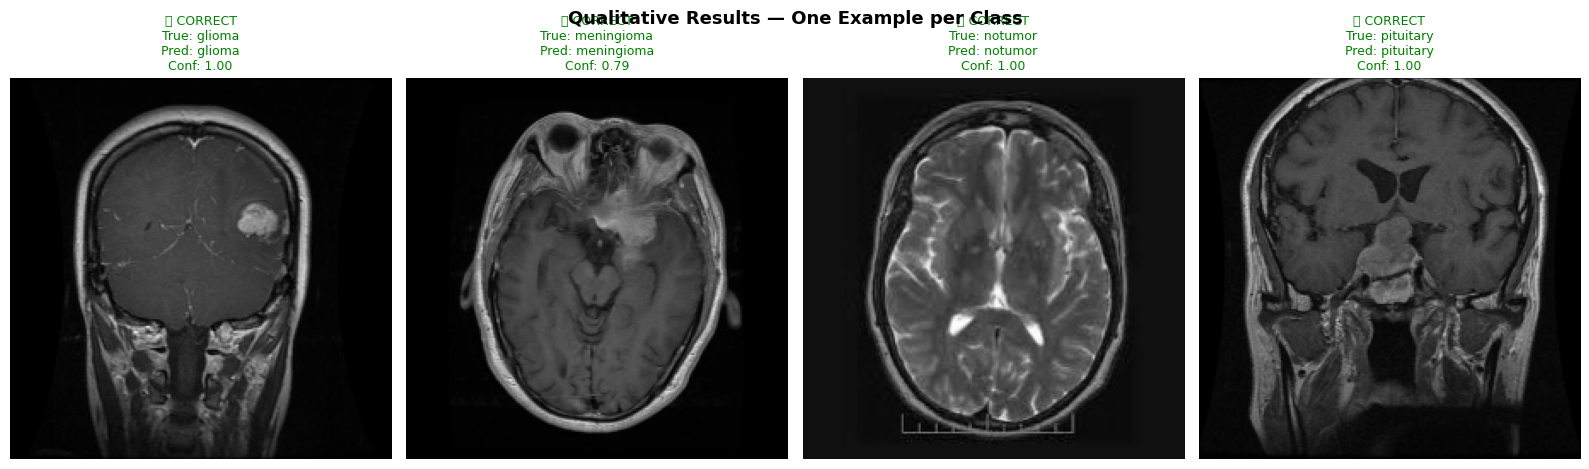

In [ ]:
filepaths   = np.array(test_gen.filepaths)
true_labels = np.array(test_gen.classes)

chosen_idx = []
for cls_idx in range(NUM_CLASSES):
    idxs = np.where(true_labels == cls_idx)[0]
    if len(idxs) > 0:
        chosen_idx.append(idxs[0])
chosen_idx = np.array(chosen_idx[:4])

X_sample = []
for fp in filepaths[chosen_idx]:
    raw = cv2.imread(fp)
    raw = cv2.cvtColor(raw, cv2.COLOR_BGR2RGB)
    raw = cv2.resize(raw, (IMG_SIZE, IMG_SIZE)).astype('float32') / 255.0
    X_sample.append(raw)
X_sample = np.array(X_sample)
y_sample_true = true_labels[chosen_idx]

probs = best_model.predict(X_sample, verbose=0)
y_sample_pred = np.argmax(probs, axis=1)
confidence_s  = np.max(probs, axis=1)

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
fig.suptitle('Qualitative Results — One Example per Class', fontsize=13, fontweight='bold')
for i in range(len(chosen_idx)):
    ok = y_sample_pred[i] == y_sample_true[i]
    axes[i].imshow(X_sample[i])
    axes[i].set_title(
        f"{'✅ CORRECT' if ok else '❌ WRONG'}\nTrue: {CLASS_NAMES[y_sample_true[i]]}\nPred: {CLASS_NAMES[y_sample_pred[i]]}\nConf: {confidence_s[i]:.2f}",
        fontsize=9, color='green' if ok else 'red')
    axes[i].axis('off')
plt.tight_layout()
plt.savefig('09_qualitative_results.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
## Section 13B: Model Size & Inference Time Analysis

import time

# Model size
model_path = 'best_trial3.keras'
if os.path.exists(model_path):
    size_mb = os.path.getsize(model_path) / (1024 * 1024)
    print(f'📦 Model Size: {size_mb:.2f} MB')

# Parameter count
total_params     = best_model.count_params()
trainable_params = sum([tf.size(w).numpy() for w in best_model.trainable_weights])
print(f'🔢 Total Parameters    : {total_params:,}')
print(f'🔢 Trainable Parameters: {trainable_params:,}')

# Inference time — single image
test_gen.reset()
X_sample, _ = next(test_gen)
single_img = X_sample[0:1]

# Warmup
_ = best_model.predict(single_img, verbose=0)

# Measure
times = []
for _ in range(50):
    start = time.time()
    _ = best_model.predict(single_img, verbose=0)
    times.append((time.time() - start) * 1000)

print(f'\n⚡ Inference Time (single image):')
print(f'   Mean : {np.mean(times):.2f} ms')
print(f'   Std  : {np.std(times):.2f} ms')
print(f'   Min  : {np.min(times):.2f} ms')

# Batch inference time
batch_times = []
for _ in range(20):
    start = time.time()
    _ = best_model.predict(X_sample, verbose=0)
    batch_times.append((time.time() - start) * 1000)

print(f'\n⚡ Inference Time (batch of {len(X_sample)}):')
print(f'   Mean : {np.mean(batch_times):.2f} ms')
print(f'   Per image: {np.mean(batch_times)/len(X_sample):.2f} ms')

🔢 Total Parameters    : 13,996,851
🔢 Trainable Parameters: 13,873,900

⚡ Inference Time (single image):
   Mean : 107.52 ms
   Std  : 27.37 ms
   Min  : 79.05 ms

⚡ Inference Time (batch of 32):
   Mean : 664.43 ms
   Per image: 20.76 ms


##  Section 14: Save Final Model

In [ ]:
# Save the final best model
best_model.save('/content/drive/MyDrive/BrainTumor_Checkpoints/BRGS_BrainTumor_FinalModel.keras')

print('=' * 55)
print('  ✅ FINAL MODEL SAVED: BRGS_BrainTumor_FinalModel.keras')
print('=' * 55)
print()
print('📊 FINAL SUMMARY')
print('-' * 55)
print(f'  Model         : Hybrid (EfficientNetB3 + MobileNetV2)')
print(f'  Attention     : Squeeze-and-Excitation')
print(f'  Best Trial    : trial3')
print(f'  Val Accuracy  : {val_acc*100:.2f}%')
print(f'  Test Accuracy : {test_acc*100:.2f}%')
print(f'  F1 Macro      : {f1_macro:.4f}')
print(f'  Precision     : {precision_macro:.4f}')
print(f'  Recall        : {recall_macro:.4f}')
print('-' * 55)
print('  XAI           : Grad-CAM Applied ✅')
print('  Noise Removal : Gaussian + Bilateral ✅')
print('  Imbalance     : Class Weights Applied ✅')
print('=' * 55)

  ✅ FINAL MODEL SAVED: BRGS_BrainTumor_FinalModel.keras

📊 FINAL SUMMARY
-------------------------------------------------------
  Model         : Hybrid (EfficientNetB3 + MobileNetV2)
  Attention     : Squeeze-and-Excitation
  Best Trial    : trial3
  Val Accuracy  : 99.72%
  Test Accuracy : 99.16%
  F1 Macro      : 0.9915
  Precision     : 0.9914
  Recall        : 0.9917
-------------------------------------------------------
  XAI           : Grad-CAM Applied ✅
  Noise Removal : Gaussian + Bilateral ✅
  Imbalance     : Class Weights Applied ✅


In [16]:
print(train_gen, val_gen, test_gen, class_weight_dict)


<keras.src.legacy.preprocessing.image.DirectoryIterator object at 0x7fbd8dbee7e0> <keras.src.legacy.preprocessing.image.DirectoryIterator object at 0x7fbd8e16c620> <keras.src.legacy.preprocessing.image.DirectoryIterator object at 0x7fbd95b6c470> {0: np.float64(1.103395061728395), 1: np.float64(1.0074476650563606), 2: np.float64(0.89375), 3: np.float64(1.0181041497152157)}


In [17]:
## Section 15: Ablation Study — Component Contribution Analysis
import json, time

ABLATION_EPOCHS = 15   # keep modest; increase if you have time/GPU budget
CKPT_DIR = '/content/drive/MyDrive/BrainTumor_Checkpoints'

def cosine_lr_schedule(epoch, lr, total_epochs=ABLATION_EPOCHS, warmup=2, base_lr=3e-4, min_lr=1e-6):
    if epoch < warmup:
        return base_lr * (epoch + 1) / warmup
    progress = (epoch - warmup) / max(1, (total_epochs - warmup))
    return min_lr + 0.5 * (base_lr - min_lr) * (1 + np.cos(np.pi * progress))

def get_ablation_callbacks(name):
    return [
        EarlyStopping(monitor='val_accuracy', patience=6, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-8, verbose=1),
        ModelCheckpoint(f'{CKPT_DIR}/ablation_{name}.keras', monitor='val_accuracy',
                        save_best_only=True, verbose=1),
        keras.callbacks.LearningRateScheduler(cosine_lr_schedule, verbose=0)
    ]

def build_se_block(x, ratio=8):
    ch = x.shape[-1]
    s = layers.Dense(ch // ratio, activation='relu')(x)
    s = layers.Dense(ch, activation='sigmoid')(s)
    return layers.Multiply()([x, s])

def classifier_head(x):
    x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    return layers.Dense(NUM_CLASSES, activation='softmax')(x)

def evaluate_variant(model, name):
    test_gen.reset()
    y_pred = np.argmax(model.predict(test_gen, verbose=0), axis=1)
    y_true = test_gen.classes
    acc  = (y_pred == y_true).mean()
    prec = precision_score(y_true, y_pred, average='macro')
    rec  = recall_score(y_true, y_pred, average='macro')
    f1   = f1_score(y_true, y_pred, average='macro')
    n_params = model.count_params()
    print(f'\n📊 {name}: Acc={acc:.4f}  Prec={prec:.4f}  Rec={rec:.4f}  F1={f1:.4f}  Params={n_params:,}')
    return {'variant': name, 'test_acc': float(acc), 'precision': float(prec),
            'recall': float(rec), 'f1': float(f1), 'params': int(n_params)}

results_ablation = []

# ── Variant 1: EfficientNetB3 only ──────────────────────────
print('🚀 Training Variant 1: EfficientNetB3 only ...')
inp = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
base_eff = EfficientNetB3(include_top=False, weights='imagenet', input_tensor=inp, pooling='avg')
x = layers.Dense(256, activation='relu')(base_eff.output)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
out = classifier_head(x)
model_eff_only = Model(inp, out)
model_eff_only.compile(optimizer=keras.optimizers.Adam(learning_rate=3e-4, clipnorm=1.0),
                        loss='categorical_crossentropy', metrics=['accuracy'])

train_gen.reset(); val_gen.reset()
model_eff_only.fit(train_gen, validation_data=val_gen, epochs=ABLATION_EPOCHS,
                    class_weight=class_weight_dict,
                    callbacks=get_ablation_callbacks('effnet_only'), verbose=1)
results_ablation.append(evaluate_variant(model_eff_only, 'EfficientNetB3 only'))
del model_eff_only; keras.backend.clear_session()

# ── Variant 2: MobileNetV2 only ─────────────────────────────
print('🚀 Training Variant 2: MobileNetV2 only ...')
inp = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
base_mob = MobileNetV2(include_top=False, weights='imagenet', input_tensor=inp, pooling='avg')
x = layers.Dense(256, activation='relu')(base_mob.output)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
out = classifier_head(x)
model_mob_only = Model(inp, out)
model_mob_only.compile(optimizer=keras.optimizers.Adam(learning_rate=3e-4, clipnorm=1.0),
                        loss='categorical_crossentropy', metrics=['accuracy'])

train_gen.reset(); val_gen.reset()
model_mob_only.fit(train_gen, validation_data=val_gen, epochs=ABLATION_EPOCHS,
                    class_weight=class_weight_dict,
                    callbacks=get_ablation_callbacks('mobilenet_only'), verbose=1)
results_ablation.append(evaluate_variant(model_mob_only, 'MobileNetV2 only'))
del model_mob_only; keras.backend.clear_session()

# ── Variant 3: Fusion WITHOUT SE attention ──────────────────
print('🚀 Training Variant 3: Fusion without SE attention ...')
inp = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
base_eff = EfficientNetB3(include_top=False, weights='imagenet', pooling='avg')
base_mob = MobileNetV2(include_top=False, weights='imagenet', pooling='avg')
base_eff._name = 'efficientnetb3_branch'
base_mob._name = 'mobilenetv2_branch'

e = base_eff(inp)
e = layers.Dense(256, activation='relu')(e)
e = layers.BatchNormalization()(e)
e = layers.Dropout(0.3)(e)

m = base_mob(inp)
m = layers.Dense(256, activation='relu')(m)
m = layers.BatchNormalization()(m)
m = layers.Dropout(0.3)(m)

fused = layers.Concatenate()([e, m])          # <-- no SE block here, straight to head
out = classifier_head(fused)
model_no_se = Model(inp, out)
model_no_se.compile(optimizer=keras.optimizers.Adam(learning_rate=3e-4, clipnorm=1.0),
                     loss='categorical_crossentropy', metrics=['accuracy'])

train_gen.reset(); val_gen.reset()
model_no_se.fit(train_gen, validation_data=val_gen, epochs=ABLATION_EPOCHS,
                 class_weight=class_weight_dict,
                 callbacks=get_ablation_callbacks('fusion_no_se'), verbose=1)
results_ablation.append(evaluate_variant(model_no_se, 'Fusion (no SE attention)'))
del model_no_se; keras.backend.clear_session()

# ── Add the full proposed model's known result for comparison ──
results_ablation.append({
    'variant': 'Full model (EffNetB3+MobileNetV2+SE) [proposed]',
    'test_acc': 0.9916, 'precision': 0.9914, 'recall': 0.9917, 'f1': 0.9915,
    'params': 13996851
})

# ── Print & save final ablation table ───────────────────────
print('\n' + '='*70)
print('ABLATION STUDY RESULTS')
print('='*70)
print(f"{'Variant':<45}{'Acc':>8}{'F1':>8}{'Params':>12}")
print('-'*70)
for r in results_ablation:
    print(f"{r['variant']:<45}{r['test_acc']*100:>7.2f}%{r['f1']:>8.4f}{r['params']:>12,}")

with open(f'{CKPT_DIR}/ablation_results.json', 'w') as f:
    json.dump(results_ablation, f, indent=2)
print(f'\n✅ Saved: {CKPT_DIR}/ablation_results.json')

🚀 Training Variant 1: EfficientNetB3 only ...
Epoch 1/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4826 - loss: 1.4453
Epoch 1: val_accuracy improved from None to 0.25536, saving model to /content/drive/MyDrive/BrainTumor_Checkpoints/ablation_effnet_only.keras

Epoch 1: finished saving model to /content/drive/MyDrive/BrainTumor_Checkpoints/ablation_effnet_only.keras
157/157 ━━━━━━━━━━━━━━━━━━━━ 381s 1s/step - accuracy: 0.6270 - loss: 1.0405 - val_accuracy: 0.2554 - val_loss: 1.4527 - learning_rate: 1.5000e-04
Epoch 2/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 516ms/step - accuracy: 0.8581 - loss: 0.4247
Epoch 2: val_accuracy did not improve from 0.25536
157/157 ━━━━━━━━━━━━━━━━━━━━ 85s 538ms/step - accuracy: 0.8753 - loss: 0.3849 - val_accuracy: 0.2516 - val_loss: 1.5083 - learning_rate: 3.0000e-04
Epoch 3/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 516ms/step - accuracy: 0.9285 - loss: 0.2265
Epoch 3: val_accuracy improved from 0.25536 to 0.28239, saving model to /content/drive/MyDrive/Bra